# Phase 4: Does the method generalize? (second model: SmolLM2-1.7B)

The Phase 2c pipeline (probe tensor families -> fit a damage model -> solve exactly -> verify on the full test split) gave 0.8-1.7% lower perplexity than the imatrix presets at equal or smaller size on Qwen2.5-1.5B, with speed on par or better on the laptop. **One model proves little.** This notebook repeats the whole pipeline on a model from a **different family and architecture**: SmolLM2-1.7B (Llama architecture, 24 blocks, multi-head attention without grouped-query sharing, a much smaller embedding share: about 6% of the weights instead of 15%).

**Why not Qwen2.5-0.5B (my earlier suggestion).** Its hidden size is 896 = 3.5 x 256, so most of its tensors cannot use K-quants: llama.cpp would silently swap in other formats. That breaks the size model and the meaning of the levels. This notebook **checks the model before doing anything expensive** and stops with a clear message if the rows are not multiples of 256. SmolLM2-1.7B has 2048 and 8192, which are fine. To try another model, change `MODEL_ID` in the config cell (the check protects you).

**What is different from Phase 2c**
- The budgets are **derived from the measured preset sizes** (Q3_K_M, Q4_K_M and two points between), so nothing is hard-coded to one model.
- No replay of old results; the damage model is calibrated only on families whose damage is clearly measurable (and falls back to the 6-dB law with a warning otherwise).
- At the end a plain-text `results/report.txt` holds all measurements, so even if the notebook outputs are lost, the file in the Output tab has everything.

**How to run it (important, to avoid losing the run again)**
1. Set Accelerator = GPU T4 x2 (or P100) and Internet = On.
2. **First run only the cells down to and including the self-test (section 5) interactively.** About 30-40 minutes. This catches model-specific problems (tokenizer conversion, tensor shapes, size model) cheaply. If something fails, paste me the output.
3. Then either continue interactively and **File -> Download Notebook after each stage**, or use **Save Version -> Save & Run All (Commit)** for the whole thing: the committed version keeps the Output files (including the models and `report.txt`) after the session ends.

**Time (rough estimate, not measured):** about 4-5 GPU hours in total (similar to the 1.5B run; a full test pass is the slow part).

In [4]:
import os, json, re, time, subprocess, pathlib, shutil, random, math
import numpy as np

os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # measure on ONE GPU even if Kaggle gives T4 x2

MODEL_ID    = "HuggingFaceTB/SmolLM2-1.7B"    # any model whose weight rows are multiples of 256 (checked below)
MODEL_NAME  = MODEL_ID.split("/")[-1]
PIN         = "6b9ba4f"       # llama.cpp commit used for the Qwen results, kept for comparability

LEVELS      = ["q3_k", "q4_k", "q5_k", "q6_k", "q8_0"]   # allowed per-tensor types, low -> high bits
HIGH        = LEVELS[-1]
N_EDGE      = 2               # first/last N blocks are the "edge" families
IMX_CHUNKS  = 200
SEARCH_CHUNKS = 80            # chunks of the SEARCH text (train slice) used for probes
TEST_CHUNKS = None            # None = the full test split

PROBE_LEVELS = ["q3_k", "q4_k"]                         # every family is probed at these
CAL_FAMS     = ["token_embd:all", "ffn_down:mid", "ffn_up:mid"]   # large families also probed at CAL_LEVELS
CAL_LEVELS   = ["q5_k", "q6_k"]
RANDOM_PER_BUDGET = 2                                    # random-allocation controls at the two in-between budgets
PRESETS      = ["Q2_K", "Q3_K_M", "Q4_K_M", "Q5_K_M"]   # the preset curve to beat

BENCH       = True            # GPU tokens/s for presets and DP configs
RUN_HELLASWAG = False
HS_TASKS    = 400
SAVE_FINAL_GGUFS = True       # write presets and in-between DP configs into results/final_models
CLEANUP     = True

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))
for host in ["github.com", "huggingface.co", "pypi.org"]:
    r = subprocess.run(["curl", "-sS", "-o", "/dev/null", "-m", "10", "-w", "%{http_code}", f"https://{host}"],
                       capture_output=True, text=True)
    print(host, "->", r.stdout or r.stderr.strip())

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5
github.com -> 200
huggingface.co -> 200
pypi.org -> 200


## 1. Build llama.cpp at the pinned commit

In [5]:
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone https://github.com/ggml-org/llama.cpp {LLAMA}")
        r = subprocess.run(f"git -C {LLAMA} checkout {PIN}", shell=True, text=True, capture_output=True)
        print("pinned to", PIN if r.returncode == 0 else f"FAILED ({r.stderr.strip()[:150]}), using the latest commit instead")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"
    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-perplexity llama-imatrix llama-bench")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT, "| matches Phase 3:", LLAMA_COMMIT.startswith(PIN[:6]))
print("per-tensor override flag available:", "--tensor-type" in sh(f"{BIN/'llama-quantize'} --help", check=False))

$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: 6b9ba4f2e | matches Phase 3: True
$ /kaggle/working/llama.cpp/build/bin/llama-quantize --help
per-tensor override flag available: True


## 2. Model, F16 GGUF and text slices
`--no-deps` keeps pip from touching numpy (last time a mid-session numpy change broke SciPy).
- **imatrix text:** first 3M characters of the WikiText-2 *train* split
- **search text:** a different 300k-character slice of *train* (used for accept/reject decisions)
- **test text:** the *test* split (only for reported numbers)

In [6]:
sh(f"pip install -q --no-deps {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID, local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"])
N_BLOCKS = json.load(open(pathlib.Path(hf_dir) / "config.json"))["num_hidden_layers"]
print("transformer blocks:", N_BLOCKS)

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

def get_text(split):
    try:
        from datasets import load_dataset
        return "".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)["text"])
    except Exception as e:
        print("datasets route failed, using parquet:", repr(e)[:150])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", f"wikitext-2-raw-v1/{split}-00000-of-00001.parquet",
                            repo_type="dataset")
        return "".join(pd.read_parquet(p)["text"])

WIKI, IMX_TEXT, SEARCH_TEXT = WORK / "wiki.test.raw", WORK / "imx.train.txt", WORK / "search.train.txt"
if not WIKI.exists():
    WIKI.write_text(get_text("test"))
if not IMX_TEXT.exists() or not SEARCH_TEXT.exists():
    train = get_text("train")
    assert len(train) > 5_400_000, "train split shorter than expected"
    IMX_TEXT.write_text(train[:3_000_000])
    SEARCH_TEXT.write_text(train[5_000_000:5_300_000])
print({p.name: f"{p.stat().st_size/1e6:.2f} MB" for p in (WIKI, IMX_TEXT, SEARCH_TEXT)})

$ pip install -q --no-deps /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

transformer blocks: 24
$ python /kaggle/working/llama.cpp/convert_hf_to_gguf.py /kaggle/working/hf/SmolLM2-1.7B --outfile /kaggle/working/models/SmolLM2-1.7B-F16.gguf --outtype f16
SmolLM2-1.7B-F16.gguf 3425 MB


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

{'wiki.test.raw': '1.29 MB', 'imx.train.txt': '3.01 MB', 'search.train.txt': '0.30 MB'}


## 3. Importance matrix (saved to `results/` for reuse)

In [7]:
IMATRIX = MODELS / f"{MODEL_NAME}.imatrix"
IMATRIX_SAVED = RESULTS / f"{MODEL_NAME}.imatrix"
if IMATRIX_SAVED.exists() and not IMATRIX.exists():
    shutil.copy(IMATRIX_SAVED, IMATRIX)
if not IMATRIX.exists():
    t = time.time()
    sh(f"{BIN/'llama-imatrix'} -m {F16} -f {IMX_TEXT} -o {IMATRIX} -ngl 99 -c 512 --chunks {IMX_CHUNKS}")
    shutil.copy(IMATRIX, IMATRIX_SAVED)
    print(f"imatrix done in {time.time()-t:.0f}s")
print("imatrix:", IMATRIX.name, f"{IMATRIX.stat().st_size/1e6:.1f} MB")

$ /kaggle/working/llama.cpp/build/bin/llama-imatrix -m /kaggle/working/models/SmolLM2-1.7B-F16.gguf -f /kaggle/working/imx.train.txt -o /kaggle/working/models/SmolLM2-1.7B.imatrix -ngl 99 -c 512 --chunks 200
imatrix done in 98s
imatrix: SmolLM2-1.7B.imatrix 4.0 MB


## 4. Helpers
`eval_file` evaluates one GGUF on several texts at once, so a single (slow) quantization serves all measurements of a configuration. The helper cell also **checks that every weight row is a multiple of 256** and stops otherwise.

In [8]:
BPW = {"q3_k": 3.4375, "q4_k": 4.5, "q5_k": 5.5, "q6_k": 6.5625, "q8_0": 8.5}
BPW_ALL = {**BPW, "q2_k": 2.625, "q4_0": 4.5, "q5_0": 5.5, "q4_1": 5.0, "q5_1": 6.0, "f16": 16.0, "bf16": 16.0, "f32": 32.0}

def exact_regex(names):
    return "^(" + "|".join(re.escape(n) for n in names) + ")$"

def run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError("failed: " + " ".join(map(str, cmd))[:300])
    return r.stdout, r.stderr

QUANT, PPLBIN, BENCHBIN = (str(BIN / n) for n in ("llama-quantize", "llama-perplexity", "llama-bench"))

def quantize(out, base, overrides=(), imatrix=True):
    cmd = [QUANT, "--imatrix", str(IMATRIX)] if imatrix else [QUANT]
    for pattern, qtype in overrides:
        cmd += ["--tensor-type", f"{pattern}={qtype}"]
    cmd += [str(F16), str(out), base]
    run(cmd)

def perplexity(path, text, chunks):
    cmd = [PPLBIN, "-m", str(path), "-f", str(text), "-ngl", "99", "-c", "512"]
    if chunks:
        cmd += ["--chunks", str(chunks)]
    so, se = run(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", so + se)
    if not m:
        raise RuntimeError((so + se)[-2000:])
    return float(m.group(1)), float(m.group(2))

def bench(path):
    so, se = run([BENCHBIN, "-m", str(path), "-p", "512", "-n", "128", "-r", "3", "-ngl", "99", "-o", "json"])
    rows = json.loads(so[so.index("["):])
    pp = next(r for r in rows if r["n_prompt"] > 0 and r["n_gen"] == 0)
    tg = next(r for r in rows if r["n_gen"] > 0 and r["n_prompt"] == 0)
    return pp["avg_ts"], tg["avg_ts"]

HS_FILE = WORK / "hellaswag_val_full.txt"
HS_OK = [RUN_HELLASWAG]
def hellaswag(path):
    if not HS_OK[0]:
        return None
    try:
        if not HS_FILE.exists():
            import urllib.request
            urllib.request.urlretrieve("https://raw.githubusercontent.com/klosax/hellaswag_text_data/main/hellaswag_val_full.txt", HS_FILE)
        so, se = run([PPLBIN, "-m", str(path), "-f", str(HS_FILE), "--hellaswag",
                      "--hellaswag-tasks", str(HS_TASKS), "-ngl", "99"])
        rows = re.findall(r"^\s*(\d+)\s+([\d.]+)%", so + se, re.M)
        return float(rows[-1][1]) if rows else None
    except Exception as e:
        print("hellaswag skipped:", repr(e)[:200])
        HS_OK[0] = False
        return None

def tensor_types(path):
    from gguf import GGUFReader
    return {t.name: t.tensor_type.name for t in GGUFReader(str(path)).tensors}

# groups = every 2-D weight matrix of the model (norms and biases are 1-D and stay F32)
from gguf import GGUFReader
GROUPS = [{"id": t.name, "n": int(t.n_elements)} for t in GGUFReader(str(F16)).tensors if len(t.shape) == 2]
_pat = re.compile(r"blk\.(\d+)\.(\w+)\.weight")
for g in GROUPS:
    m = _pat.fullmatch(g["id"])
    g["block"] = int(m.group(1)) if m else -1
    g["kind"] = m.group(2) if m else g["id"].replace(".weight", "")
N_ELEM = np.array([g["n"] for g in GROUPS], dtype=float)
G = len(GROUPS)
HI = len(LEVELS) - 1
print(f"{G} weight tensors, {N_ELEM.sum()/1e6:.0f}M weights")

# K-quants need rows that are multiples of 256; otherwise llama.cpp silently swaps in other formats
bad = [(t.name, int(t.shape[0])) for t in GGUFReader(str(F16)).tensors if len(t.shape) == 2 and int(t.shape[0]) % 256 != 0]
if bad:
    raise RuntimeError(f"{len(bad)} weight tensors have a row length that is not a multiple of 256, for example {bad[:3]}. "
                       "llama.cpp would replace the K-quant types for them with other formats, which breaks the size model "
                       "and the meaning of the levels. Choose a model whose hidden and intermediate sizes are multiples of 256.")
print("OK: every weight row is a multiple of 256, so the K-quant levels apply as assumed")

FIXED_BYTES = None            # set by the self-test
BPW_VEC = np.array([BPW[l] for l in LEVELS])
def size_mb(idx):
    return (FIXED_BYTES + (N_ELEM * BPW_VEC[idx] / 8.0).sum()) / 1e6

def overrides_from_idx(idx):
    by_level = {}
    for g, l in zip(GROUPS, idx):
        if LEVELS[l] != HIGH:
            by_level.setdefault(LEVELS[l], []).append(g["id"])
    return [(exact_regex(names), lvl) for lvl, names in by_level.items()]

RESULTS_FILE = RESULTS / f"phase2c_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["name"]] = r

def log(name, rec, **meta):
    rec = {"name": name, **rec, **meta}
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    return rec

SPEC_SEARCH = {"search": (SEARCH_TEXT, SEARCH_CHUNKS)}
SPEC_HEAD   = {"search": (SEARCH_TEXT, SEARCH_CHUNKS), "full": (WIKI, TEST_CHUNKS)}

def eval_file(path, specs, do_bench=False, do_hs=False):
    rec = {"size_mb": path.stat().st_size / 1e6}
    for key, (text, chunks) in specs.items():
        rec[f"ppl_{key}"], rec[f"err_{key}"] = perplexity(path, text, chunks)
    if do_bench and BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(path)
    if do_hs:
        rec["hellaswag"] = hellaswag(path)
    return rec

def short(rec):
    ppls = "  ".join(f"ppl[{k[4:]}]={rec[k]:.4f}" for k in rec if k.startswith("ppl_"))
    return ppls + f"  size={rec['size_mb']:.1f} MB  {rec['secs']:.0f}s"

def evaluate_multi(name, idx, specs, do_bench=False, do_hs=False, **meta):
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, HIGH, overrides_from_idx(idx))
    rec = eval_file(out, specs, do_bench, do_hs)
    out.unlink()
    rec["secs"] = time.time() - t
    print(f"{name[:38]:38s} {short(rec)}")
    return log(name, rec, levels=[LEVELS[int(i)] for i in idx], **meta)

def idx_of(rec):
    return np.array([LEVELS.index(l) for l in rec["levels"]])

def dump(prefixes):
    # print records as compact JSON lines: they stay inside the notebook file when you download it
    for name, r in records.items():
        if any(name.startswith(p) for p in prefixes):
            print(json.dumps({k: (round(v, 5) if isinstance(v, float) else v)
                              for k, v in r.items() if k not in ("levels", "types", "move")}))

169 weight tensors, 1711M weights
OK: every weight row is a multiple of 256, so the K-quant levels apply as assumed


## 5. Self-test (run before anything long)
Per-tensor overrides must apply, and the size model must match real file sizes. The numbers feed the search's feasibility check, so a failure here must be fixed first.

In [9]:
plain = MODELS / "selftest_plain.gguf"; mixed = MODELS / "selftest_mixed.gguf"
quantize(plain, HIGH, [], imatrix=False)
FIXED_BYTES = plain.stat().st_size - (N_ELEM * BPW[HIGH] / 8.0).sum()      # norms, biases, metadata
print(f"fixed (non-group) bytes: {FIXED_BYTES/1e6:.1f} MB")

a, b = GROUPS[0], GROUPS[-1] if GROUPS[-1]["id"] != GROUPS[0]["id"] else GROUPS[1]
quantize(mixed, HIGH, [(exact_regex([a["id"]]), "q3_k"), (exact_regex([b["id"]]), "q5_k")], imatrix=False)
tt = tensor_types(mixed)
print(a["id"], "->", tt[a["id"]], "|", b["id"], "->", tt[b["id"]])
others = {v for k, v in tt.items() if k not in (a["id"], b["id"]) and "norm" not in k and not k.endswith(".bias")}
print("all other weight tensors:", others)
idx_t = np.full(G, len(LEVELS) - 1)
idx_t[0 if a is GROUPS[0] else 1] = LEVELS.index("q3_k")
idx_t[G - 1 if b is GROUPS[-1] else 1] = LEVELS.index("q5_k")
pred, act = size_mb(idx_t), mixed.stat().st_size / 1e6
print(f"size model: predicted {pred:.1f} MB, actual {act:.1f} MB, error {100*(pred/act-1):+.2f}%")
plain.unlink(); mixed.unlink()
assert tt[a["id"]] == "Q3_K" and tt[b["id"]] == "Q5_K" and others == {"Q8_0"}, "overrides not applied as expected: paste this output"
assert abs(pred / act - 1) < 0.02, "size model off by more than 2%: paste this output"
print("OK: overrides and size model work")

fixed (non-group) bytes: 2.2 MB
token_embd.weight -> Q3_K | blk.9.attn_v.weight -> Q5_K
all other weight tensors: {'Q8_0'}
size model: predicted 1755.1 MB, actual 1755.1 MB, error +0.00%
OK: overrides and size model work


> **Stop here for the first interactive run.** If everything above printed without errors (the model converted, the divisibility check says OK, the overrides and the size model pass), continue. Otherwise paste me the output.

## 5b. Family definitions and the exact solver

In [10]:
# ---- families: (tensor kind) x (position bucket) --------------------------------
def bucket_of(g):
    if g["block"] < 0:
        return "all"
    if g["block"] < N_EDGE:
        return "lo"
    if g["block"] >= N_BLOCKS - N_EDGE:
        return "hi"
    return "mid"

for g in GROUPS:
    g["fam"] = f"{g['kind']}:{bucket_of(g)}"
FAMS = sorted({g["fam"] for g in GROUPS})
FAM_GROUPS = {f: np.array([i for i, g in enumerate(GROUPS) if g["fam"] == f]) for f in FAMS}


FAM_N = {f: float(N_ELEM[FAM_GROUPS[f]].sum()) for f in FAMS}
def apply_move(idx, move):
    new = idx.copy()
    for fam, d in move:
        sel = FAM_GROUPS[fam]
        new[sel] = np.clip(new[sel] + d, 0, len(LEVELS) - 1)
    return new


print(len(FAMS), 'families:', FAMS)

22 families: ['attn_k:hi', 'attn_k:lo', 'attn_k:mid', 'attn_output:hi', 'attn_output:lo', 'attn_output:mid', 'attn_q:hi', 'attn_q:lo', 'attn_q:mid', 'attn_v:hi', 'attn_v:lo', 'attn_v:mid', 'ffn_down:hi', 'ffn_down:lo', 'ffn_down:mid', 'ffn_gate:hi', 'ffn_gate:lo', 'ffn_gate:mid', 'ffn_up:hi', 'ffn_up:lo', 'ffn_up:mid', 'token_embd:all']


In [11]:
def solve_dp(D, S, cap, unit=20_000.0):
    # Exact multiple-choice knapsack by dynamic programming: one level per family,
    # total bytes <= cap, minimise total predicted damage. Sizes are rounded UP to 'unit'
    # bytes, so the result never exceeds the cap (it can waste at most F*unit bytes).
    F, L = D.shape
    W = np.ceil(S / unit).astype(int)
    U = int(cap // unit)
    INF = 1e18
    dp = np.zeros(U + 1)                         # best damage using the families so far with total <= s
    choice = np.zeros((F, U + 1), dtype=np.int8)
    for f in range(F):
        new = np.full(U + 1, INF)
        ch = np.zeros(U + 1, dtype=np.int8)
        for l in range(L):
            w = int(W[f, l])
            if w > U:
                continue
            cand = np.full(U + 1, INF)
            cand[w:] = dp[:U + 1 - w] + D[f, l]
            better = cand < new
            new[better] = cand[better]
            ch[better] = l
        dp, choice[f] = new, ch
    if dp[U] >= INF / 2:
        raise ValueError("budget is smaller than the cheapest possible allocation")
    idx = np.zeros(F, dtype=int)
    s = U
    for f in range(F - 1, -1, -1):
        idx[f] = choice[f, s]
        s -= int(W[f, idx[f]])
    return idx, float(dp[U])

def random_alloc(S, cap, rng, tol=0.985, tries=200_000):
    # a random level per family whose size lands within [tol*cap, cap]: the "no model" control
    F, L = S.shape
    for _ in range(tries):
        idx = np.array([rng.randrange(L) for _ in range(F)])
        s = S[np.arange(F), idx].sum()
        if tol * cap <= s <= cap:
            return idx
    raise RuntimeError("could not draw a random allocation inside the size window")

# unit test: DP must match brute force on a small random instance
rng_t = np.random.default_rng(3)
F_t, L_t = 6, len(LEVELS)
N_t = rng_t.integers(1_000_000, 30_000_000, F_t).astype(float)
S_t = np.array([[n * BPW[l] / 8.0 for l in LEVELS] for n in N_t])
D_t = rng_t.lognormal(-5, 1, F_t)[:, None] * np.array([1.0, 0.25, 0.06, 0.015, 0.0])[None, :]
cap_t = 0.55 * S_t[:, -1].sum() + 0.45 * S_t[:, 0].sum()
import itertools
best = min((D_t[np.arange(F_t), c].sum(), c) for c in itertools.product(range(L_t), repeat=F_t)
           if S_t[np.arange(F_t), c].sum() <= cap_t)
idx_t, dmg_t = solve_dp(D_t, S_t, cap_t, unit=1_000.0)
print(f"brute force {best[0]:.6f} | DP {dmg_t:.6f} | DP size ok: {S_t[np.arange(F_t), idx_t].sum() <= cap_t}")
assert S_t[np.arange(F_t), idx_t].sum() <= cap_t and dmg_t <= best[0] * 1.02, "DP is not near-optimal: paste this output"
print("OK: solver works")

brute force 0.000443 | DP 0.000443 | DP size ok: True
OK: solver works


## 6. Stage A: the presets (the curve to beat)
Each imatrix preset is evaluated once on the search text (80 chunks) and on the **full** test split, plus GPU speed. The sizes of Q3_K_M and Q4_K_M then define the budgets.

In [12]:
def nearest_level(tname):
    b = BPW_ALL.get(tname.lower(), 8.5)
    return min(range(len(LEVELS)), key=lambda i: abs(BPW[LEVELS[i]] - b))

def preset_record(q):
    name = f"preset_imx_{q}"
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, q, [], imatrix=True)
    tt = tensor_types(out)
    idx = [nearest_level(tt[g["id"]]) for g in GROUPS]
    unmapped = sum(1 for g in GROUPS if tt[g["id"]].lower() not in BPW)
    rec = eval_file(out, SPEC_HEAD, do_bench=True)
    out.unlink()
    rec["secs"] = time.time() - t
    print(f"{name:38s} {short(rec)}  unmapped tensors={unmapped}")
    return log(name, rec, levels=[LEVELS[i] for i in idx], types=[tt[g["id"]] for g in GROUPS], unmapped=unmapped)

for q in PRESETS:
    preset_record(q)
dump(["preset_imx_"])

# budgets derived from the measured preset sizes: Q3_K_M, two points in between, Q4_K_M (floored to 0.1 MB so we never exceed a preset)
s3, s4 = records["preset_imx_Q3_K_M"]["size_mb"], records["preset_imx_Q4_K_M"]["size_mb"]
fl = lambda x: math.floor(x * 10) / 10
BUDGETS_MB = [fl(s3), fl(s3 + (s4 - s3) / 3), fl(s3 + 2 * (s4 - s3) / 3), fl(s4)]
RANDOM_BUDGETS = BUDGETS_MB[1:3]
SAVE_BUDGETS = BUDGETS_MB[1:3]
print("budgets (MB):", BUDGETS_MB)

preset_imx_Q2_K                        ppl[search]=11.0990  ppl[full]=12.3576  size=674.6 MB  274s  unmapped tensors=96
preset_imx_Q3_K_M                      ppl[search]=8.3638  ppl[full]=9.4087  size=860.2 MB  220s  unmapped tensors=0
preset_imx_Q4_K_M                      ppl[search]=7.8628  ppl[full]=8.8016  size=1055.6 MB  262s  unmapped tensors=0
preset_imx_Q5_K_M                      ppl[search]=7.7319  ppl[full]=8.6537  size=1225.5 MB  268s  unmapped tensors=0
{"name": "preset_imx_Q2_K", "size_mb": 674.58291, "ppl_search": 11.099, "err_search": 0.199, "ppl_full": 12.3576, "err_full": 0.08358, "pp_tps": 3028.55288, "tg_tps": 136.52406, "secs": 274.01212, "unmapped": 96}
{"name": "preset_imx_Q3_K_M", "size_mb": 860.18086, "ppl_search": 8.3638, "err_search": 0.14627, "ppl_full": 9.4087, "err_full": 0.06266, "pp_tps": 3665.68452, "tg_tps": 125.74147, "secs": 220.14156, "unmapped": 0}
{"name": "preset_imx_Q4_K_M", "size_mb": 1055.60922, "ppl_search": 7.8628, "err_search": 0.1353, "p

## 7. Stage B: damage of every tensor family
Each family is set to q3_k and to q4_k with everything else at q8_0 (all tensors of the family at once). The three calibration families are also probed at q5_k and q6_k. About 50 evaluations.

In [13]:
ref = evaluate_multi("ref_q8", np.full(G, HI), SPEC_SEARCH, group="ref")
ref_s = ref["ppl_search"]
print("reference (all q8_0) search ppl:", round(ref_s, 4))

def family_cfg(fam, lvl):
    cfg = np.full(G, HI)
    cfg[FAM_GROUPS[fam]] = LEVELS.index(lvl)
    return cfg

t0 = time.time()
for f in sorted(FAMS, key=lambda f: -FAM_N[f]):
    for l in PROBE_LEVELS:
        evaluate_multi(f"probe_{f}_{l}", family_cfg(f, l), SPEC_SEARCH, group="probe", fam=f, level=l)
for f in CAL_FAMS:
    for l in CAL_LEVELS:
        evaluate_multi(f"probe_{f}_{l}", family_cfg(f, l), SPEC_SEARCH, group="probe", fam=f, level=l)
print(f"probing took {(time.time()-t0)/60:.0f} min in this run (0 if everything was cached)")

ref_q8                                 ppl[search]=7.6543  size=1820.4 MB  28s
reference (all q8_0) search ppl: 7.6543
probe_ffn_down:mid_q3_k                ppl[search]=7.8376  size=1608.1 MB  35s
probe_ffn_down:mid_q4_k                ppl[search]=7.7094  size=1652.6 MB  57s
probe_ffn_gate:mid_q3_k                ppl[search]=7.7639  size=1608.1 MB  36s
probe_ffn_gate:mid_q4_k                ppl[search]=7.6769  size=1652.6 MB  57s
probe_ffn_up:mid_q3_k                  ppl[search]=7.7996  size=1608.1 MB  35s
probe_ffn_up:mid_q4_k                  ppl[search]=7.6885  size=1652.6 MB  57s
probe_token_embd:all_q3_k              ppl[search]=9.2056  size=1756.7 MB  29s
probe_token_embd:all_q4_k              ppl[search]=8.0730  size=1770.1 MB  33s
probe_attn_k:mid_q3_k                  ppl[search]=7.7062  size=1767.3 MB  30s
probe_attn_k:mid_q4_k                  ppl[search]=7.6708  size=1778.5 MB  35s
probe_attn_output:mid_q3_k             ppl[search]=7.7512  size=1767.3 MB  30s
probe_attn_o

In [14]:
dump(["ref_q8", "probe_"])

{"name": "ref_q8", "size_mb": 1820.41434, "ppl_search": 7.6543, "err_search": 0.13111, "secs": 28.10211, "group": "ref"}
{"name": "probe_ffn_down:mid_q3_k", "size_mb": 1608.0777, "ppl_search": 7.8376, "err_search": 0.13369, "secs": 35.34321, "group": "probe", "fam": "ffn_down:mid", "level": "q3_k"}
{"name": "probe_ffn_down:mid_q4_k", "size_mb": 1652.64218, "ppl_search": 7.7094, "err_search": 0.13202, "secs": 57.28173, "group": "probe", "fam": "ffn_down:mid", "level": "q4_k"}
{"name": "probe_ffn_gate:mid_q3_k", "size_mb": 1608.0777, "ppl_search": 7.7639, "err_search": 0.13293, "secs": 35.51296, "group": "probe", "fam": "ffn_gate:mid", "level": "q3_k"}
{"name": "probe_ffn_gate:mid_q4_k", "size_mb": 1652.64218, "ppl_search": 7.6769, "err_search": 0.13143, "secs": 57.21618, "group": "probe", "fam": "ffn_gate:mid", "level": "q4_k"}
{"name": "probe_ffn_up:mid_q3_k", "size_mb": 1608.0777, "ppl_search": 7.7996, "err_search": 0.13385, "secs": 35.47184, "group": "probe", "fam": "ffn_up:mid", "le

## 8. Fit the damage model
`r(l)` (how fast damage shrinks with more bits) is calibrated on the calibration families whose q3_k damage is clearly measurable (at least 0.01 nats); with fewer than two such families the 6-dB-per-bit law is used instead and a warning is printed. The per-family scale `a_family` is a least-squares fit through the origin.

In [15]:
LAW = {l: 2.0 ** (-2 * (BPW[l] - BPW["q3_k"])) for l in LEVELS}
def dmg(f, l):                                       # damage in nats
    return math.log(records[f"probe_{f}_{l}"]["ppl_search"] / ref_s)

valid_cal = [f for f in CAL_FAMS if dmg(f, "q3_k") >= 0.01]
print("calibration families usable (q3_k damage >= 0.01 nats):", valid_cal)
print("measured damage ratio vs q3_k (calibration families):")
ratios = {l: [] for l in ["q4_k", "q5_k", "q6_k"]}
for f in CAL_FAMS:
    d3 = dmg(f, "q3_k")
    row = {l: dmg(f, l) / d3 for l in ratios if f"probe_{f}_{l}" in records}
    if f in valid_cal:
        for l, v in row.items():
            ratios[l].append(v)
    print(f"  {f:16s} q3_k damage {d3:+.4f} nats | " + "  ".join(f"{l} {v:.3f}" for l, v in row.items()) +
          ("" if f in valid_cal else "   (too small, not used)"))
R = {"q3_k": 1.0}
for l in ["q4_k", "q5_k", "q6_k"]:
    R[l] = float(np.median(ratios[l])) if len(valid_cal) >= 2 and ratios[l] else LAW[l]
if len(valid_cal) < 2:
    print("WARNING: fewer than two usable calibration families, using the 6-dB-per-bit law for r(l)")
prev = 1.0
for l in ["q4_k", "q5_k", "q6_k"]:                   # damage must not grow with more bits
    R[l] = min(R[l], prev); prev = R[l]
R["q8_0"] = 0.0
print("fitted r(l):", {l: round(v, 4) for l, v in R.items()}, "| law:", {l: round(LAW[l], 4) for l in LEVELS})

A = {}
for f in FAMS:
    num = den = 0.0
    for l in LEVELS[:-1]:
        if f"probe_{f}_{l}" in records:
            num += dmg(f, l) * R[l]; den += R[l] ** 2
    A[f] = max(num / den, 0.0)
D = np.array([[A[f] * R[l] for l in LEVELS] for f in FAMS])                          # predicted damage (nats)
S = np.array([[FAM_N[f] * BPW[l] / 8.0 for l in LEVELS] for f in FAMS])               # bytes

import pandas as pd
tab = pd.DataFrame({"family": FAMS, "params_M": [FAM_N[f] / 1e6 for f in FAMS],
                    "q3_k_nats": [dmg(f, "q3_k") for f in FAMS], "q4_k_nats": [dmg(f, "q4_k") for f in FAMS],
                    "scale_a": [A[f] for f in FAMS]}).sort_values("q3_k_nats", ascending=False)
display(tab.round(4).reset_index(drop=True))
print("families whose q3_k damage is below 0.003 nats are near the noise floor:",
      [f for f in FAMS if dmg(f, "q3_k") < 0.003])

calibration families usable (q3_k damage >= 0.01 nats): ['token_embd:all', 'ffn_down:mid', 'ffn_up:mid']
measured damage ratio vs q3_k (calibration families):
  token_embd:all   q3_k damage +0.1845 nats | q4_k 0.289  q5_k 0.050  q6_k 0.010
  ffn_down:mid     q3_k damage +0.0237 nats | q4_k 0.303  q5_k 0.089  q6_k 0.024
  ffn_up:mid       q3_k damage +0.0188 nats | q4_k 0.237  q5_k 0.096  q6_k -0.007
fitted r(l): {'q3_k': 1.0, 'q4_k': 0.2886, 'q5_k': 0.0888, 'q6_k': 0.0101, 'q8_0': 0.0} | law: {'q3_k': 1.0, 'q4_k': 0.2293, 'q5_k': 0.0573, 'q6_k': 0.0131, 'q8_0': 0.0009}


,family,params_M,q3_k_nats,q4_k_nats,scale_a
0,token_embd:all,100.6633,0.1845,0.0533,0.1840
1,attn_v:mid,83.8861,0.0322,0.0038,0.0307
2,ffn_down:mid,335.5443,0.0237,0.0072,0.0238
3,ffn_up:mid,335.5443,0.0188,0.0045,0.0186
4,ffn_down:hi,33.5544,0.0161,0.0022,0.0155
5,ffn_gate:mid,335.5443,0.0142,0.0029,0.0139
6,ffn_up:hi,33.5544,0.0127,0.0024,0.0124
7,attn_output:mid,83.8861,0.0126,0.0022,0.0122
8,attn_q:mid,83.8861,0.0080,0.0022,0.0079
9,attn_v:lo,8.3886,0.0074,0.0009,0.0070


families whose q3_k damage is below 0.003 nats are near the noise floor: ['attn_k:hi', 'attn_k:lo', 'attn_output:hi', 'attn_output:lo', 'attn_q:hi', 'attn_q:lo', 'ffn_gate:lo', 'ffn_up:lo']


## 9. Solve for the budgets

In [16]:
FIXED = FIXED_BYTES
def expand(fam_idx):                                  # family levels -> per-tensor level array
    cfg = np.zeros(G, dtype=int)
    for k, f in enumerate(FAMS):
        cfg[FAM_GROUPS[f]] = fam_idx[k]
    return cfg

plans, rand_plans = {}, {}
for B in BUDGETS_MB:
    cap = B * 1e6 - FIXED
    fi, pred = solve_dp(D, S, cap)
    plans[B] = fi
    cfg = expand(fi)
    print(f"budget {B} MB: predicted size {size_mb(cfg):.1f} MB, predicted damage {pred:.4f} nats "
          f"({100*(math.exp(pred)-1):.2f}% perplexity over q8_0)")
for B in RANDOM_BUDGETS:
    cap = B * 1e6 - FIXED
    for i in range(RANDOM_PER_BUDGET):
        fi = random_alloc(S, cap, random.Random(f"rnd-{B}-{i}"))
        rand_plans[(B, i)] = fi
        print(f"random {B} MB #{i}: size {size_mb(expand(fi)):.1f} MB, predicted damage {D[np.arange(len(FAMS)), fi].sum():.4f}")

bits = pd.DataFrame({f"{B} MB": [BPW[LEVELS[l]] for l in plans[B]] for B in BUDGETS_MB}, index=FAMS)
print("\nbits per weight chosen for each family:")
display(bits)

budget 860.1 MB: predicted size 858.9 MB, predicted damage 0.0819 nats (8.53% perplexity over q8_0)
budget 925.3 MB: predicted size 924.7 MB, predicted damage 0.0575 nats (5.92% perplexity over q8_0)
budget 990.4 MB: predicted size 989.7 MB, predicted damage 0.0397 nats (4.05% perplexity over q8_0)
budget 1055.6 MB: predicted size 1055.3 MB, predicted damage 0.0260 nats (2.63% perplexity over q8_0)
random 925.3 MB #0: size 917.7 MB, predicted damage 0.0890
random 925.3 MB #1: size 918.9 MB, predicted damage 0.2635
random 990.4 MB #0: size 986.7 MB, predicted damage 0.0690
random 990.4 MB #1: size 986.9 MB, predicted damage 0.1183

bits per weight chosen for each family:


,860.1 MB,925.3 MB,990.4 MB,1055.6 MB
attn_k:hi,4.5000,4.5000,4.5000,4.5000
attn_k:lo,3.4375,4.5000,4.5000,4.5000
attn_k:mid,3.4375,4.5000,4.5000,4.5000
attn_output:hi,4.5000,4.5000,5.5000,5.5000
attn_output:lo,5.5000,5.5000,6.5625,5.5000
attn_output:mid,4.5000,4.5000,5.5000,5.5000
attn_q:hi,5.5000,5.5000,5.5000,5.5000
attn_q:lo,3.4375,3.4375,3.4375,3.4375
attn_q:mid,4.5000,4.5000,4.5000,5.5000
attn_v:hi,5.5000,5.5000,6.5625,5.5000


## 10. Stage C: verify with real runs on the full test split

In [17]:
for B in BUDGETS_MB:
    cfg = expand(plans[B])
    evaluate_multi(f"dp_{B}", cfg, SPEC_HEAD, do_bench=True, group="dp", budget=B,
                   pred_dmg=float(D[np.arange(len(FAMS)), plans[B]].sum()),
                   fam_levels={f: LEVELS[l] for f, l in zip(FAMS, plans[B])})
for (B, i), fi in rand_plans.items():
    evaluate_multi(f"rnd_{B}_{i}", expand(fi), SPEC_HEAD, group="rnd", budget=B,
                   pred_dmg=float(D[np.arange(len(FAMS)), fi].sum()),
                   fam_levels={f: LEVELS[l] for f, l in zip(FAMS, fi)})
dump(["dp_", "rnd_"])

dp_860.1                               ppl[search]=8.2784  ppl[full]=9.3402  size=858.9 MB  210s
dp_925.3                               ppl[search]=8.0944  ppl[full]=9.1087  size=924.7 MB  232s
dp_990.4                               ppl[search]=7.9646  ppl[full]=8.9286  size=989.7 MB  248s
dp_1055.6                              ppl[search]=7.8479  ppl[full]=8.7757  size=1055.3 MB  266s
rnd_925.3_0                            ppl[search]=8.2952  ppl[full]=9.3435  size=917.7 MB  213s
rnd_925.3_1                            ppl[search]=10.0360  ppl[full]=11.4356  size=918.9 MB  206s
rnd_990.4_0                            ppl[search]=8.1427  ppl[full]=9.1524  size=986.7 MB  226s
rnd_990.4_1                            ppl[search]=8.6125  ppl[full]=9.6851  size=986.9 MB  195s
{"name": "dp_860.1", "size_mb": 858.93568, "ppl_search": 8.2784, "err_search": 0.14143, "ppl_full": 9.3402, "err_full": 0.06102, "pp_tps": 3617.73496, "tg_tps": 119.91829, "secs": 209.60424, "group": "dp", "budget": 860.1

## 11. Results
`vs_curve_pct` compares each configuration with the imatrix-preset curve at the same size (monotone interpolation of log-perplexity through the 4 presets): **positive = better than the presets**. At the Q3_K_M and Q4_K_M sizes the comparison is with the real presets.

In [18]:
import matplotlib.pyplot as plt
df = pd.DataFrame([{k: v for k, v in r.items() if k not in ("levels", "types", "move", "fam_levels")}
                   for r in records.values()])
pre = df[df.name.str.startswith("preset_imx_")].sort_values("size_mb")
try:
    from scipy.interpolate import PchipInterpolator
    curve = PchipInterpolator(pre.size_mb.values, np.log(pre.ppl_full.values))
    curve_fn = lambda s: float(np.exp(curve(s))) if pre.size_mb.min() <= s <= pre.size_mb.max() else float("nan")
except Exception as e:
    print("scipy interpolation unavailable, using log-linear interpolation:", repr(e)[:80])
    curve_fn = lambda s: float(np.exp(np.interp(s, pre.size_mb.values, np.log(pre.ppl_full.values), left=np.nan, right=np.nan)))

res = df[df.name.str.match(r"^(preset_imx_|dp_|rnd_)")].copy()
res["curve_ppl_at_size"] = res.size_mb.apply(curve_fn)
res["vs_curve_pct"] = (res.curve_ppl_at_size / res.ppl_full - 1) * 100
cols = [c for c in ["name", "size_mb", "ppl_search", "ppl_full", "curve_ppl_at_size", "vs_curve_pct", "tg_tps"] if c in res.columns]
display(res.sort_values("size_mb")[cols].round(4).reset_index(drop=True))

for B in (BUDGETS_MB[0], BUDGETS_MB[-1]):
    pr = "preset_imx_Q3_K_M" if B == BUDGETS_MB[0] else "preset_imx_Q4_K_M"
    p, d = records[pr], records[f"dp_{B}"]
    print(f"{B} MB: preset {p['ppl_full']:.4f} vs allocation {d['ppl_full']:.4f} -> {100*(p['ppl_full']/d['ppl_full']-1):+.2f}% "
          f"| GPU tok/s {p.get('tg_tps', float('nan')):.1f} vs {d.get('tg_tps', float('nan')):.1f}")

,name,size_mb,ppl_search,ppl_full,curve_ppl_at_size,vs_curve_pct,tg_tps
0,preset_imx_Q2_K,674.5829,11.0990,12.3576,12.3576,0.0000,136.5241
1,dp_860.1,858.9357,8.2784,9.3402,9.4153,0.8043,119.9183
2,preset_imx_Q3_K_M,860.1809,8.3638,9.4087,9.4087,-0.0000,125.7415
3,rnd_925.3_0,917.7215,8.2952,9.3435,9.1482,-2.0897,NaN
4,rnd_925.3_1,918.9011,10.0360,11.4356,9.1437,-20.0416,NaN
5,dp_925.3,924.6683,8.0944,9.1087,9.1220,0.1462,128.6593
6,rnd_990.4_0,986.7309,8.1427,9.1524,8.9316,-2.4122,NaN
7,rnd_990.4_1,986.9275,8.6125,9.6851,8.9311,-7.7847,NaN
8,dp_990.4,989.6800,7.9646,8.9286,8.9244,-0.0469,120.6430
9,dp_1055.6,1055.3471,7.8479,8.7757,8.8020,0.2991,132.3723


860.1 MB: preset 9.4087 vs allocation 9.3402 -> +0.73% | GPU tok/s 125.7 vs 119.9
1055.6 MB: preset 8.8016 vs allocation 8.7757 -> +0.30% | GPU tok/s 135.6 vs 132.4


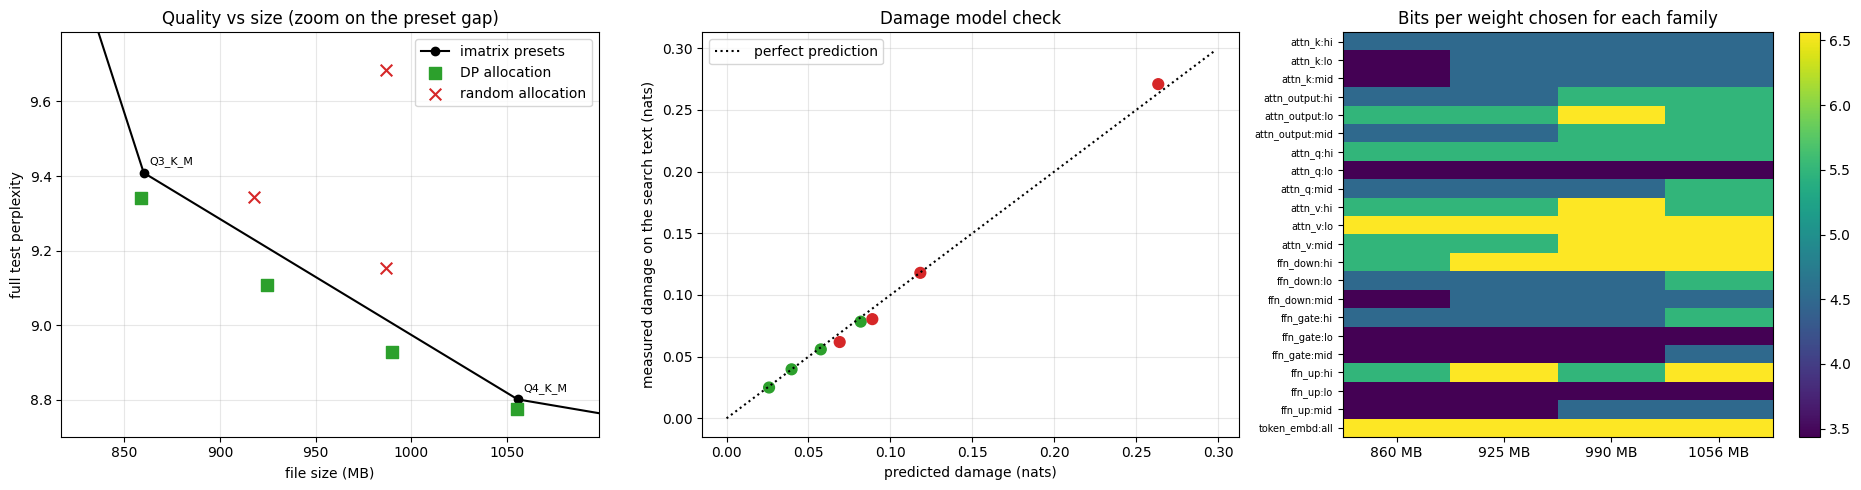

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
a = ax[0]
a.plot(pre.size_mb, pre.ppl_full, "ko-", label="imatrix presets", zorder=3)
for _, r in pre.iterrows():
    a.annotate(r["name"].replace("preset_imx_", ""), (r.size_mb, r.ppl_full), textcoords="offset points", xytext=(4, 6), fontsize=8)
for pref, col, mk, lb in [("dp_", "tab:green", "s", "DP allocation"), ("rnd_", "tab:red", "x", "random allocation")]:
    d = res[res.name.str.startswith(pref)]
    if len(d):
        a.scatter(d.size_mb, d.ppl_full, c=col, marker=mk, s=70, label=lb, zorder=4)
gap = pre[(pre.size_mb >= s3 * 0.97) & (pre.size_mb <= s4 * 1.03)]
a.set_xlim(s3 * 0.95, s4 * 1.04); a.set_ylim(gap.ppl_full.min() - 0.1, gap.ppl_full.max() * 1.04)
a.set_xlabel("file size (MB)"); a.set_ylabel("full test perplexity"); a.set_title("Quality vs size (zoom on the preset gap)")
a.legend(); a.grid(alpha=.3)

b = ax[1]
mine = res[res.name.str.match(r"^(dp_|rnd_)")].copy()
mine["pred"] = [records[n]["pred_dmg"] for n in mine.name]
mine["actual"] = [math.log(records[n]["ppl_search"] / ref_s) for n in mine.name]
b.scatter(mine.pred, mine.actual, c=["tab:green" if n.startswith("dp_") else "tab:red" for n in mine.name], s=60)
lim = max(mine.pred.max(), mine.actual.max()) * 1.1
b.plot([0, lim], [0, lim], "k:", label="perfect prediction")
b.set_xlabel("predicted damage (nats)"); b.set_ylabel("measured damage on the search text (nats)")
b.set_title("Damage model check"); b.legend(); b.grid(alpha=.3)

c = ax[2]
im = c.imshow(bits.values, aspect="auto", cmap="viridis")
c.set_xticks(range(len(BUDGETS_MB))); c.set_xticklabels([f"{B:.0f} MB" for B in BUDGETS_MB])
c.set_yticks(range(len(FAMS))); c.set_yticklabels(FAMS, fontsize=7)
c.set_title("Bits per weight chosen for each family"); plt.colorbar(im, ax=c)
plt.tight_layout()
plt.savefig(RESULTS / f"phase4_{MODEL_NAME}_summary.png", dpi=150)
plt.show()

## 12. Save results, a plain-text report, and the models for the laptop; then clean up

In [20]:
res.to_csv(RESULTS / f"phase4_{MODEL_NAME}_results.csv", index=False)
tab.to_csv(RESULTS / f"phase4_{MODEL_NAME}_family_damage.csv", index=False)
allocs = {f"{B}": {f: LEVELS[l] for f, l in zip(FAMS, plans[B])} for B in BUDGETS_MB}
(RESULTS / f"phase4_{MODEL_NAME}_allocations.json").write_text(json.dumps(allocs, indent=1))
meta = {"model": MODEL_ID, "llama_cpp_commit": LLAMA_COMMIT, "levels": LEVELS, "ratios": R, "scales": A,
        "budgets": BUDGETS_MB, "search_chunks": SEARCH_CHUNKS, "test_chunks": TEST_CHUNKS,
        "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
        "date": time.strftime("%Y-%m-%d %H:%M")}
(RESULTS / f"phase4_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=1))

# plain-text report: every measurement as a JSON line plus the main tables (survives even if notebook outputs are lost)
lines = ["# phase 4 report, " + MODEL_ID, json.dumps(meta), "", res.sort_values("size_mb")[cols].round(4).to_string(), "",
         "## all records (JSON lines)"]
for name, r in records.items():
    lines.append(json.dumps({k: (round(v, 5) if isinstance(v, float) else v) for k, v in r.items() if k not in ("levels", "types", "move")}))
(RESULTS / f"phase4_{MODEL_NAME}_report.txt").write_text("\n".join(lines))

if SAVE_FINAL_GGUFS:
    outdir = RESULTS / "final_models"; outdir.mkdir(exist_ok=True)
    for q in ["Q3_K_M", "Q4_K_M"]:
        p = outdir / f"{MODEL_NAME}-{q}-imx.gguf"
        if not p.exists():
            quantize(p, q, [], imatrix=True)
    for B in SAVE_BUDGETS:
        p = outdir / f"{MODEL_NAME}-dp{B:.0f}.gguf"
        if not p.exists():
            quantize(p, HIGH, overrides_from_idx(expand(plans[B])), imatrix=True)
    print({p.name: f"{p.stat().st_size/1e6:.0f} MB" for p in sorted(outdir.glob('*.gguf'))})

dump(["dp_", "rnd_", "preset_imx_"])
if CLEANUP:
    shutil.rmtree(WORK / "hf", ignore_errors=True)
    shutil.rmtree(MODELS, ignore_errors=True)
    print(sh(f"du -sh {WORK}", check=False))

$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
{
 "model": "HuggingFaceTB/SmolLM2-1.7B",
 "llama_cpp_commit": "6b9ba4f2e",
 "levels": [
  "q3_k",
  "q4_k",
  "q5_k",
  "q6_k",
  "q8_0"
 ],
 "ratios": {
  "q3_k": 1.0,
  "q4_k": 0.2885894950212506,
  "q5_k": 0.08878835435942561,
  "q6_k": 0.01011403122305994,
  "q8_0": 0.0
 },
 "scales": {
  "attn_k:hi": 0.001001242736647891,
  "attn_k:lo": 0.0005818193991417078,
  "attn_k:mid": 0.006811738795166607,
  "attn_output:hi": 0.001260907601880131,
  "attn_output:lo": 0.002735134162085365,
  "attn_output:mid": 0.012207408988006686,
  "attn_q:hi": 0.0021339187731935993,
  "attn_q:lo": 0.00026763991395979176,
  "attn_q:mid": 0.007937070485528936,
  "attn_v:hi": 0.0035732785390903752,
  "attn_v:lo": 0.007022038487195558,
  "attn_v:mid": 0.03073770723887224,
  "ffn_down:hi": 0.015485084081479548,
  "ffn_down:lo": 0.0040981282397960965,
  "ffn_down:mid": 0.02375897488908177,
  "ffn_gate:hi": 0.004808491603363789,
  "ffn_gate:lo": 0.0005990

## How to read the result
1. **Presets sizes (first and last budget):** the allocation uses one level per family. Matching or beating the real preset there is the cleanest comparison. On Qwen2.5-1.5B the gains were 1.3% (Q3_K_M size) and 0.8% (Q4_K_M size).
2. **In-between sizes:** `vs_curve_pct` above zero beats interpolating between presets; the random allocations show how much is due to the solver.
3. **Model check (middle plot):** points near the diagonal mean the family-level damage model works for this model too.
4. **If it does not generalize:** report it. Possible reasons to look at: the embedding is only about 6% of this model, attention k/v are large (no grouped-query sharing), so the families that mattered most for Qwen may matter less here.
5. **Next:** copy the `.gguf` files from `results/final_models/` to the laptop and run the same `llama-bench` commands as before.